# XAI TCNER Project

## Train Base Model

In [9]:
import pandas as pd
import numpy as np
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------
# Load spaCy and define preprocessing
# ----------------------------
nlp = spacy.load("en_core_web_sm")

def preprocess(text):
    doc = nlp(text.lower())
    tokens = [
        token.lemma_ for token in doc
        if not token.is_stop and not token.is_punct and len(token) > 2
    ]
    return " ".join(tokens)

# ----------------------------
# Load data
# ----------------------------
train_df = pd.read_csv("data/DBLPTrainset.txt", sep="\t", header=None, names=["Label", "Title"])
test_df = pd.read_csv("data/DBLPTestset.txt", sep="\t", header=None, names=["Title"])
test_truth = pd.read_csv("data/DBLPTestGroundTruth.txt", sep="\t", header=None, names=["Label"])
y_test = test_truth["Label"]

# ----------------------------
# Preprocess titles
# ----------------------------
train_df["Cleaned_Title"] = train_df["Title"].apply(preprocess)
test_df["Cleaned_Title"] = test_df["Title"].apply(preprocess)

y_train = train_df["Label"]
y_test = test_truth["Label"]

print("Class Distribution in Training Set:")
print(y_train.value_counts())
print("\nClass Distribution in Test Set:")
print(y_test.value_counts())

# ----------------------------
# Data Quality Checks
# ----------------------------
train_dup_titles = train_df.duplicated(subset="Title").sum()
test_dup_titles = test_df.duplicated(subset="Title").sum()
unique_train_dup_titles = train_df[train_df.duplicated(subset="Title", keep=False)]["Title"].nunique()
train_full_row_dups = train_df.duplicated().sum()
test_full_row_dups = test_df.duplicated().sum()

print("Train duplicate titles:", train_dup_titles)
print("Unique duplicate titles in train set:", unique_train_dup_titles)
print("Train full-row duplicates:", train_full_row_dups)
print("Test duplicate titles:", test_dup_titles)
print("Test full-row duplicates:", test_full_row_dups)

train_df = train_df.drop_duplicates(subset="Title", keep="first")

print("\nMissing values in training set:")
print(train_df.isnull().sum())
print("\nMissing values in test set:")
print(test_df.isnull().sum())
print("\nMissing values in test ground truth:")
print(test_truth.isnull().sum())

# ----------------------------
# Outlier Detection (Title Length)
# ----------------------------
train_df["title_char_len"] = train_df["Title"].apply(len)
test_df["title_char_len"] = test_df["Title"].apply(len)

print("\nOutlier Check - Title Lengths:")
print("Training set → Min:", train_df["title_char_len"].min(), "| Max:", train_df["title_char_len"].max())
print("Test set     → Min:", test_df["title_char_len"].min(), "| Max:", test_df["title_char_len"].max())

# ----------------------------
# TF-IDF vectorization
# ----------------------------
vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words='english',
    min_df=3,
    max_df=0.85
)

X_train = vectorizer.fit_transform(train_df["Cleaned_Title"])
X_test = vectorizer.transform(test_df["Cleaned_Title"])
y_train = train_df["Label"]

# ----------------------------
# Train model: Logistic Regression 
# ----------------------------
print("\nTraining LogisticRegression...")
model = LogisticRegression(max_iter=1000, solver='liblinear', multi_class='ovr')
model.fit(X_train, y_train)

# Predict on test set
y_pred = model.predict(X_test)

# Evaluation
print("\n=== FINAL TEST SET EVALUATION ===")
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)

Class Distribution in Training Set:
Label
ISCAS       7514
INFOCOM     4481
VLDB        3678
WWW         3292
SIGGRAPH    2678
Name: count, dtype: int64

Class Distribution in Test Set:
Label
ISCAS       2043
INFOCOM      502
WWW          423
VLDB         219
SIGGRAPH     186
Name: count, dtype: int64
Train duplicate titles: 146
Unique duplicate titles in train set: 121
Train full-row duplicates: 145
Test duplicate titles: 12
Test full-row duplicates: 12

Missing values in training set:
Label            0
Title            0
Cleaned_Title    0
dtype: int64

Missing values in test set:
Title            0
Cleaned_Title    0
dtype: int64

Missing values in test ground truth:
Label    0
dtype: int64

Outlier Check - Title Lengths:
Training set → Min: 5 | Max: 214
Test set     → Min: 10 | Max: 168

Training LogisticRegression...

=== FINAL TEST SET EVALUATION ===
Classification Report:
              precision    recall  f1-score   support

     INFOCOM       0.76      0.76      0.76       50

## LOCAL - Lime Explanations

In [13]:
import random
from lime.lime_text import LimeTextExplainer
from sklearn.pipeline import make_pipeline

In [15]:
# ----------------------------
# LIME Explanations for 10 Random Samples
# ----------------------------
print("\n=== LIME Explanations for 10 Random Samples ===")
pipeline = make_pipeline(vectorizer, model)
class_names = sorted(y_train.unique())
explainer = LimeTextExplainer(class_names=class_names)

# Choose 10 random indices from the test set
random_indices = random.sample(range(len(test_df)), 10)

for idx in random_indices:
    sample_text = test_df.iloc[idx]["Title"]
    true_label = y_test.iloc[idx]

    print(f"\n--- Sample Index: {idx} ---")
    print("Selected Title:", sample_text)
    print("True Label:", true_label)

    exp = explainer.explain_instance(sample_text, pipeline.predict_proba, num_features=10)

    print("Top Features from LIME:")
    for feature, weight in exp.as_list():
        print(f"{feature}: {weight:.4f}")

    # Optional: show HTML explanation in Jupyter
    exp.show_in_notebook(text=sample_text)


=== LIME Explanations for 10 Random Samples ===

--- Sample Index: 1014 ---
Selected Title: One-Hot Residue Coding for High-Speed Non-Uniform Pseudo-Random Test Pattern Generation.
True Label: ISCAS
Top Features from LIME:
High: 0.1420
Coding: 0.1412
Test: 0.0861
Pattern: -0.0659
Random: -0.0553
Hot: -0.0525
Speed: 0.0460
Pseudo: 0.0330
Residue: 0.0295
Non: -0.0230



--- Sample Index: 501 ---
Selected Title: Testsuite and harness for browser based editing.
True Label: WWW
Top Features from LIME:
browser: -0.0859
editing: -0.0565
harness: -0.0064
Testsuite: -0.0038
for: -0.0031
and: -0.0018
based: -0.0018



--- Sample Index: 683 ---
Selected Title: Nonuniform Sampling of Signals &amp; Applications.
True Label: ISCAS
Top Features from LIME:
Sampling: -0.0674
amp: -0.0477
Signals: -0.0035
of: -0.0027
Applications: -0.0026
Nonuniform: -0.0024



--- Sample Index: 569 ---
Selected Title: Front Matter.
True Label: VLDB
Top Features from LIME:
Matter: -0.0866
Front: 0.0307



--- Sample Index: 991 ---
Selected Title: Region Definition of Minimizing the Number of Switchboxes and Ordering Assignment.
True Label: ISCAS
Top Features from LIME:
Region: 0.0652
Number: 0.0490
Assignment: -0.0357
Ordering: -0.0230
Definition: -0.0110
Switchboxes: 0.0009
and: 0.0003
the: 0.0002
Minimizing: -0.0000
of: 0.0000



--- Sample Index: 3358 ---
Selected Title: The dual-sparse topic model: mining focused topics and focused terms in short text.
True Label: WWW
Top Features from LIME:
dual: 0.0997
text: -0.0972
topic: -0.0959
mining: -0.0913
sparse: 0.0698
focused: -0.0389
model: -0.0225
short: -0.0086
topics: 0.0021
in: -0.0021



--- Sample Index: 1548 ---
Selected Title: A Compact Array Processor Based on Self-timed Simultaneous Bidirectional Signalling.
True Label: ISCAS
Top Features from LIME:
Array: 0.1246
Processor: 0.1205
Compact: 0.0454
Bidirectional: -0.0292
Self: 0.0250
Simultaneous: 0.0087
on: 0.0017
timed: -0.0012
Signalling: -0.0012
Based: -0.0003



--- Sample Index: 2324 ---
Selected Title: Stereoscopic architectural image inpainting.
True Label: SIGGRAPH
Top Features from LIME:
Stereoscopic: -0.1788
image: 0.0759
architectural: 0.0091
inpainting: -0.0005



--- Sample Index: 2853 ---
Selected Title: Multipurpose Chip for Physiological Measurements.
True Label: ISCAS
Top Features from LIME:
Chip: 0.6359
Measurements: -0.0001
for: -0.0001
Multipurpose: -0.0001
Physiological: -0.0001



--- Sample Index: 3124 ---
Selected Title: Piecewise Linear Macromodels for Elementary Logic and Fuzzy Circuits.
True Label: ISCAS
Top Features from LIME:
Logic: 0.1341
Linear: 0.0832
Fuzzy: 0.0235
Piecewise: 0.0063
Circuits: 0.0028
Elementary: 0.0027
Macromodels: 0.0026
and: 0.0014
for: 0.0010


## LOCAL - SHAP Explanations (Misclassified Instances)

In [18]:
import shap
import numpy as np
from IPython.display import display
shap.initjs()

X_test_dense = X_test.toarray()
y_pred = model.predict(X_test)

misclassified_indices = np.where(y_pred != y_test)[0]
misclassified_indices = misclassified_indices[:5]

explainer = shap.Explainer(model, X_train[:100])
class_names = model.classes_

for idx in misclassified_indices:
    sample_dense = X_test_dense[idx].reshape(1, -1)
    shap_values = explainer(sample_dense)

    title = test_df.iloc[idx]["Title"]
    true_label = y_test.iloc[idx]
    pred_label = y_pred[idx]

    true_index = list(class_names).index(true_label)
    pred_index = list(class_names).index(pred_label)

    print(f"\n=== Misclassified Sample {idx} ===")
    print(f"Title           : {title}")
    print(f"True Label      : {true_label}")
    print(f"Predicted Label : {pred_label}")

    print("\n--> SHAP Explanation for Predicted Label")
    display(shap.force_plot(
        base_value=explainer.expected_value[pred_index],
        shap_values=shap_values.values[0][:, pred_index],
        features=sample_dense[0],
        feature_names=vectorizer.get_feature_names_out()
    ))

    print("\n--> SHAP Explanation for True Label")
    display(shap.force_plot(
        base_value=explainer.expected_value[true_index],
        shap_values=shap_values.values[0][:, true_index],
        features=sample_dense[0],
        feature_names=vectorizer.get_feature_names_out()
    ))


=== Misclassified Sample 3 ===
Title           : Efficient network generation under general preferential attachment.
True Label      : WWW
Predicted Label : INFOCOM

--> SHAP Explanation for Predicted Label


C:\Users\Admin\anaconda3\Lib\site-packages\transformers\utils\generic.py:260: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  torch.utils._pytree._register_pytree_node(



--> SHAP Explanation for True Label



=== Misclassified Sample 13 ===
Title           : Computer Formulation of Averaged Models for Periodically-Switched Networks.
True Label      : ISCAS
Predicted Label : INFOCOM

--> SHAP Explanation for Predicted Label



--> SHAP Explanation for True Label



=== Misclassified Sample 20 ===
Title           : An Efficient Four Layer Over-the-Cell Router.
True Label      : ISCAS
Predicted Label : INFOCOM

--> SHAP Explanation for Predicted Label



--> SHAP Explanation for True Label



=== Misclassified Sample 24 ===
Title           : Twins: Device-free object tracking using passive tags.
True Label      : INFOCOM
Predicted Label : ISCAS

--> SHAP Explanation for Predicted Label



--> SHAP Explanation for True Label



=== Misclassified Sample 26 ===
Title           : Learning in hide-and-seek.
True Label      : INFOCOM
Predicted Label : WWW

--> SHAP Explanation for Predicted Label



--> SHAP Explanation for True Label


## LOCAL: Anchors (Misclassified Samples)

In [21]:
import numpy as np
import random
import spacy
from alibi.explainers import AnchorText
from alibi.utils.lang_model import DistilbertBaseUncased

print("\n=== Anchor Explanations for 5 Random Misclassified Samples ===")

nlp = spacy.load("en_core_web_sm")
language_model = DistilbertBaseUncased()

def predict_fn(texts):
    return model.predict(vectorizer.transform(texts))

anchor_explainer = AnchorText(predict_fn, sampling_strategy="language_model", nlp=nlp, language_model=language_model)

X_test_dense = X_test.toarray()
y_pred = model.predict(X_test)
misclassified = np.where(y_pred != y_test)[0][:5]

for idx in misclassified:
    text = test_df.iloc[idx]["Title"]
    true = y_test.iloc[idx]
    pred = predict_fn([text])[0]
    exp = anchor_explainer.explain(text)
    print(f"\n=== Sample Index: {idx} ===")
    print("Title:", text)
    print("True Label:", true)
    print("Predicted Label:", pred)
    print("Anchor Rule:", " AND ".join(f'"{w}"' for w in exp.anchor))
    print("Precision:", round(exp.precision, 2))
    print("Coverage :", round(exp.coverage, 2))
    covered = exp.raw["examples"][-1]["covered_true"][:3]
    for ex in covered:
        print("-", ex)


=== Anchor Explanations for 5 Random Misclassified Samples ===


C:\Users\Admin\anaconda3\Lib\site-packages\spacy\util.py:910: UserWarning: [W095] Model 'en_core_web_sm' (3.8.0) was trained with spaCy v3.8.0 and may not be 100% compatible with the current version (3.7.5). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)
C:\Users\Admin\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:1150: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


TypeError: 'NoneType' object is not callable

## GLOBAL - Top Positively and Negatively Weighted Features

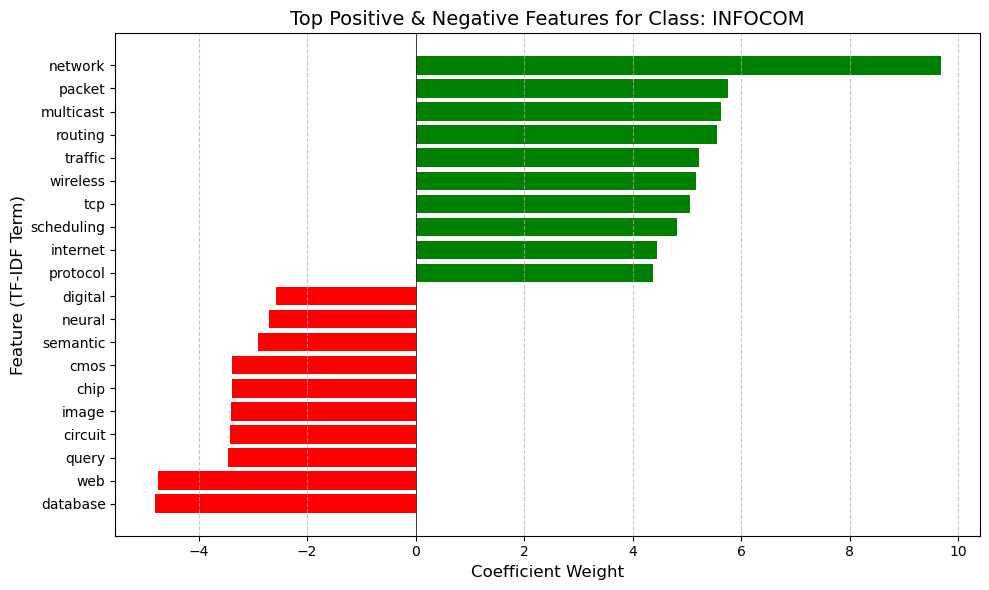

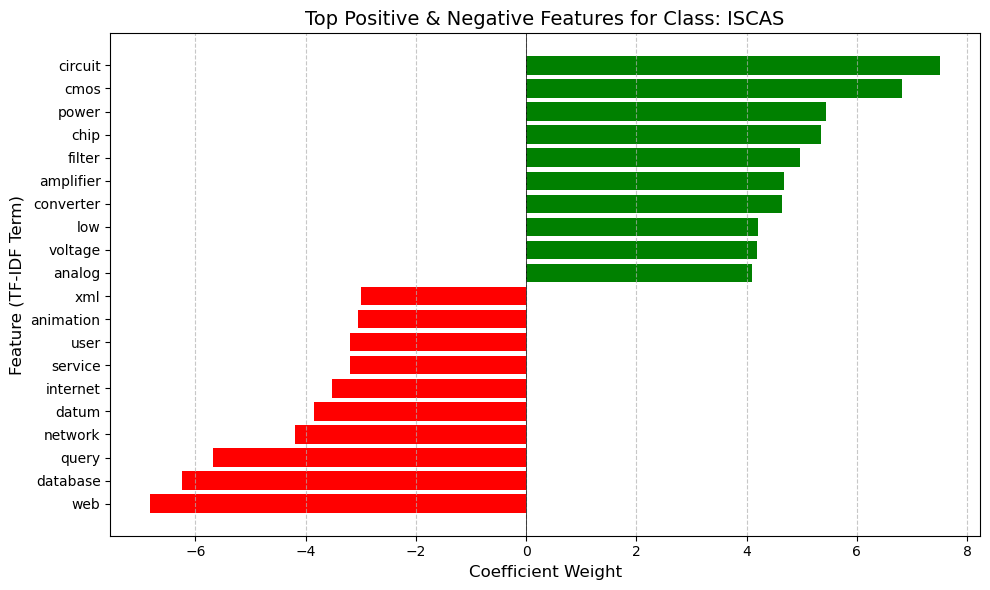

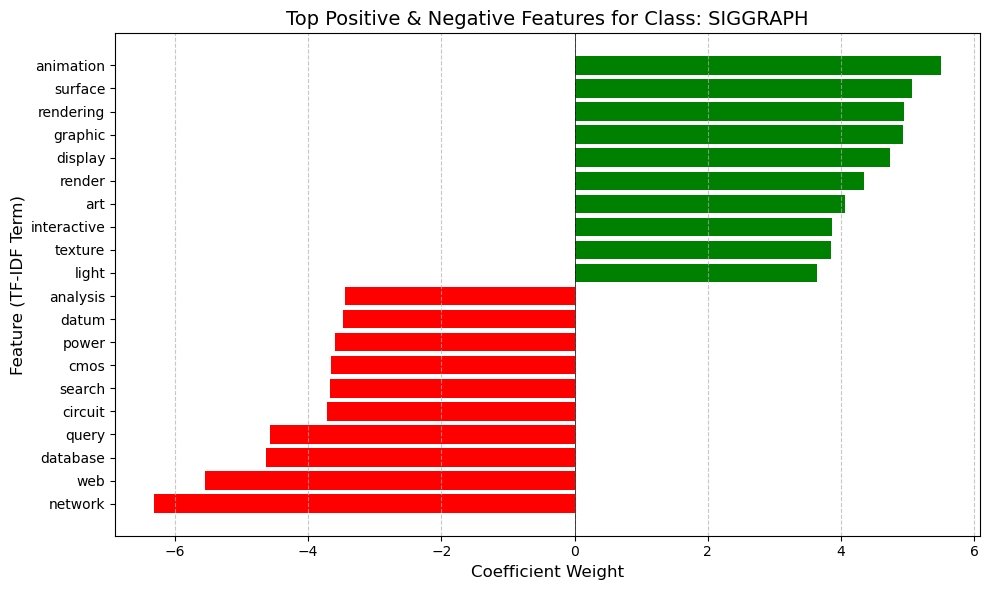

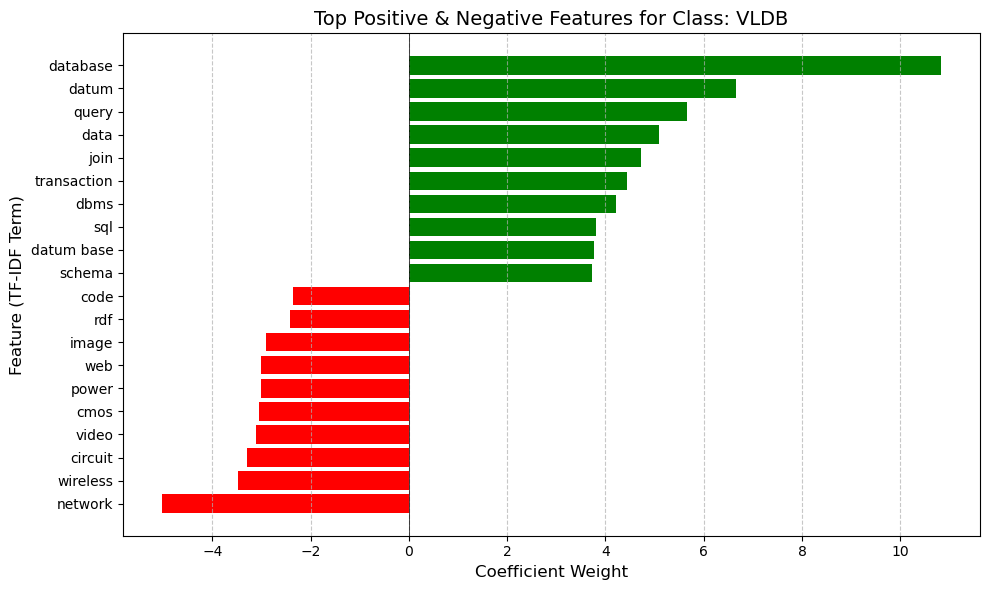

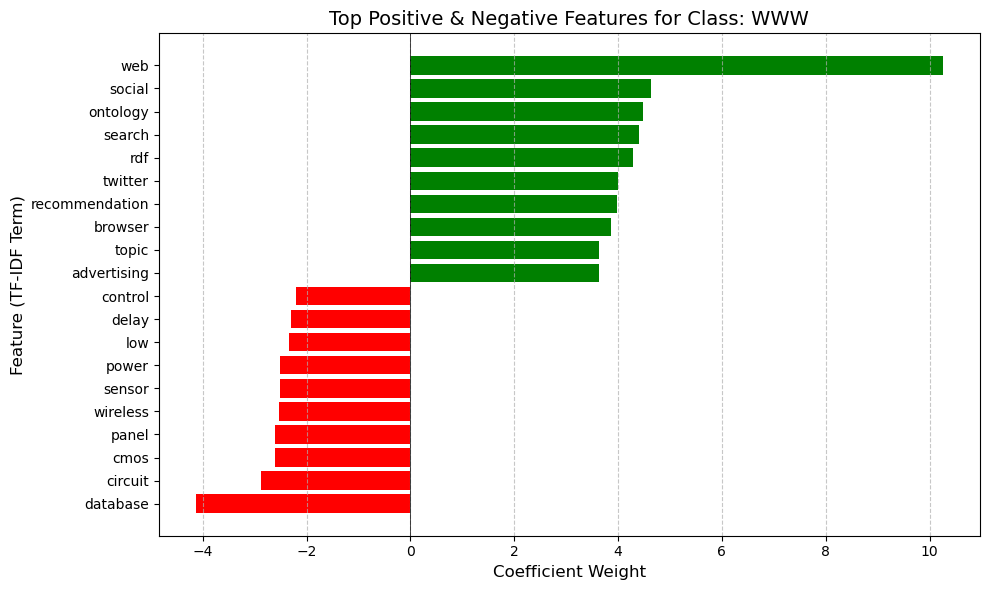

In [24]:
import numpy as np
import matplotlib.pyplot as plt

feature_names = vectorizer.get_feature_names_out()
class_labels = model.classes_
top_n = 10  # number of features to show in each direction

for i, class_label in enumerate(class_labels):
    coefs = model.coef_[i]
    
    top_pos_idx = np.argsort(coefs)[-top_n:]
    top_neg_idx = np.argsort(coefs)[:top_n]

    top_pos_features = [(feature_names[j], coefs[j]) for j in top_pos_idx]
    top_neg_features = [(feature_names[j], coefs[j]) for j in top_neg_idx]

    # Combine and sort for visual clarity
    combined = top_neg_features + top_pos_features
    combined_words = [w for w, _ in combined]
    combined_weights = [w for _, w in combined]

    colors = ['red'] * top_n + ['green'] * top_n

    plt.figure(figsize=(10, 6))
    bars = plt.barh(combined_words, combined_weights, color=colors)
    plt.axvline(0, color='black', linewidth=0.5)
    plt.title(f"Top Positive & Negative Features for Class: {class_label}", fontsize=14)
    plt.xlabel("Coefficient Weight", fontsize=12)
    plt.ylabel("Feature (TF-IDF Term)", fontsize=12)
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()


## GLOBAL - Permutation Importance


Top 20 features by permutation importance:
network              0.0368 +/- 0.0049
web                  0.0326 +/- 0.0030
matter               0.0314 +/- 0.0013
circuit              0.0306 +/- 0.0036
neural               0.0306 +/- 0.0017
filter               0.0284 +/- 0.0035
design               0.0282 +/- 0.0027
query                0.0276 +/- 0.0020
cmos                 0.0274 +/- 0.0020
current              0.0270 +/- 0.0025
function             0.0268 +/- 0.0017
social network       0.0266 +/- 0.0011
link                 0.0266 +/- 0.0011
social               0.0266 +/- 0.0033
net                  0.0264 +/- 0.0000
chip                 0.0260 +/- 0.0017
surface              0.0260 +/- 0.0012
search               0.0260 +/- 0.0015
neural network       0.0258 +/- 0.0013
online               0.0258 +/- 0.0009


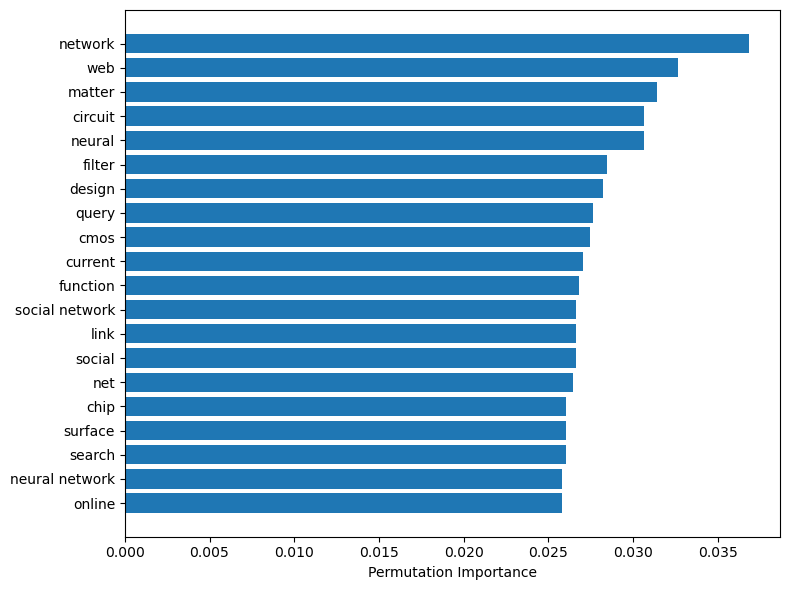

In [27]:
from sklearn.inspection import permutation_importance

X_test_dense = X_test.toarray()

results = permutation_importance(
    model,
    X_test_dense,
    y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
    max_samples=500
)

importances = results.importances_mean
stds = results.importances_std
indices = np.argsort(importances)[::-1]
feature_names = vectorizer.get_feature_names_out()

top_n = 20
print(f"\nTop {top_n} features by permutation importance:")
for idx in indices[:top_n]:
    print(f"{feature_names[idx]:<20} "
          f"{importances[idx]:.4f} +/- {stds[idx]:.4f}")

plt.figure(figsize=(8, 6))
plt.barh(
    feature_names[indices[:top_n]][::-1],
    importances[indices[:top_n]][::-1]
)
plt.xlabel("Permutation Importance")
plt.tight_layout()
plt.show()

## GLOBAL: Surrogate Model (Decision Tree)

In [30]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

surrogate = DecisionTreeClassifier(max_depth=3, random_state=42)
surrogate.fit(X_train, model.predict(X_train))

plt.figure(figsize=(20, 10))
plot_tree(
    surrogate,
    feature_names=vectorizer.get_feature_names_out(),
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.show()

InvalidParameterError: The 'feature_names' parameter of plot_tree must be an instance of 'list' or None. Got array(['10', '100', '10gbase', ..., 'zero block', 'zigbee', 'zoom'],
      dtype=object) instead.

<Figure size 2000x1000 with 0 Axes>

## LOCAL: Entropy-based confidence analysis

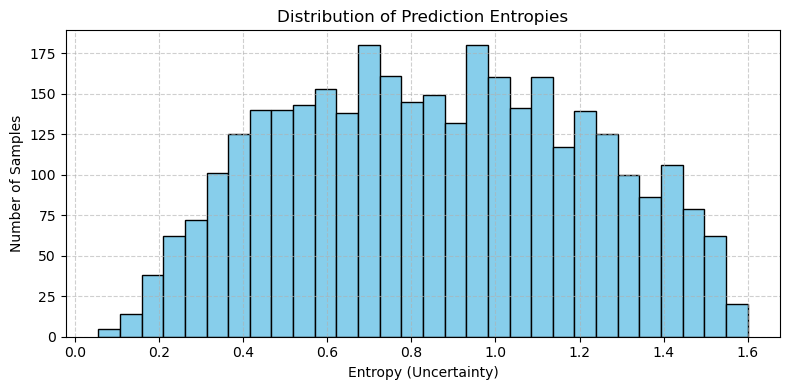


=== Top 5 Overconfident Misclassified Samples ===

Index: 1504
Entropy       : 0.3361
Title         : Matching Titles with Cross Title Web-Search Enrichment and Community Detection.
True Label    : VLDB
Predicted     : WWW

Index: 353
Entropy       : 0.3783
Title         : Deduplicating a places database.
True Label    : WWW
Predicted     : VLDB

Index: 1371
Entropy       : 0.4430
Title         : Processing scientific mesh queries in graph databases.
True Label    : WWW
Predicted     : VLDB

Index: 384
Entropy       : 0.4547
Title         : Biperpedia: An Ontology for Search Applications.
True Label    : VLDB
Predicted     : WWW

Index: 115
Entropy       : 0.5355
Title         : Silencing the noise on <i>Elysium</i>.
True Label    : SIGGRAPH
Predicted     : ISCAS


In [33]:
from scipy.stats import entropy
import matplotlib.pyplot as plt
import numpy as np

probs = model.predict_proba(X_test)
entropies = entropy(probs, axis=1)

plt.figure(figsize=(8, 4))
plt.hist(entropies, bins=30, color='skyblue', edgecolor='black')
plt.title("Distribution of Prediction Entropies")
plt.xlabel("Entropy (Uncertainty)")
plt.ylabel("Number of Samples")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

y_pred = model.predict(X_test)
misclassified_mask = y_pred != y_test.values
misclassified_indices = np.where(misclassified_mask)[0]
misclassified_entropies = entropies[misclassified_indices]

sorted_idx = misclassified_indices[np.argsort(misclassified_entropies)]

print("\n=== Top 5 Overconfident Misclassified Samples ===")
for i in sorted_idx[:5]:
    print(f"\nIndex: {i}")
    print(f"Entropy       : {entropies[i]:.4f}")
    print(f"Title         : {test_df.iloc[i]['Title']}")
    print(f"True Label    : {y_test.iloc[i]}")
    print(f"Predicted     : {y_pred[i]}")